In [1]:
# import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.initializers import GlorotUniform
from scipy import stats
from sklearn.preprocessing import StandardScaler

In [2]:
# set seeds
np.random.seed(1)
tf.random.set_seed(1)

In [3]:
# load data
# CHANGED: reads alldata.csv -- merge_features.R's already-merged, already-
# NaN-filled union of fulldata.csv and extra_features.csv -- instead of
# merging the two files here itself. Both this notebook and analyze_nets.R
# used to redo that same merge independently; merge_features.R now does it
# once, upstream, for both. It has also already 0-filled clust/uclust/
# chuclust (NaN for any degree<2 node -- the cause of the all-NaN Brier
# skill / training-curve issue found earlier), which this notebook never
# handled before.
df = pd.read_csv('alldata.csv')
df.head()


C:\Users\mthor\AppData\Local\Temp\ipykernel_40484\3953646388.py:10: DtypeWarning: Columns (0: ethnicity, 1: education, 2: gender) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('alldata.csv')


,rid,sid,trial,netid,unode,id,nnode,response,rt,binres,...,chub,chuc,chue,chuclust,chuconstr,chuecc,chuesize,vdist,vecc,uvecc
0,1,2032,1,9134,15,0,17,9,25860,0,...,15.666667,0.005039,0.255498,-0.333333,-0.212531,0,1.333333,3.053981,1.641347,1.454307
1,2,2032,1,9134,15,1,17,9,25860,0,...,9.500000,0.001979,0.053352,-0.333333,-0.212531,0,1.333333,2.207291,2.257222,1.454307
2,3,2032,1,9134,15,2,17,9,25860,0,...,17.666667,0.005750,0.292161,-0.333333,-0.212531,0,1.333333,2.968253,1.514285,1.454307
3,4,2032,1,9134,15,3,17,9,25860,0,...,15.666667,0.005039,0.255498,-0.333333,-0.212531,0,1.333333,2.683157,1.336684,1.454307
4,5,2032,1,9134,15,4,17,9,25860,0,...,18.000000,0.006501,0.261564,-0.333333,-0.212531,-1,1.333333,2.758482,1.359470,1.454307


In [4]:
# subject-level partition
usid = np.asarray(df.sid.unique()).copy()
np.random.shuffle(usid)

n = usid.size
n_train = int(round(0.70 * n))
n_val   = int(round(0.10 * n))
utrain, uval, utest = np.split(usid, [n_train, n_train + n_val])   # test absorbs remainder

# row-level masks
traindat = df.loc[df.sid.isin(utrain)].copy()
valdat   = df.loc[df.sid.isin(uval)].copy()
testdat  = df.loc[df.sid.isin(utest)].copy()

In [5]:
# z-score normalization of numeric features
numeric_features = [
    'age',                                                     # individual differences
    'degree', 'closeness', 'betweenness', 'eigenvector',       # target node
    'clust', 'constr', 'ecc', 'esize', 'comsize',               # target node (ADDED)
    'udegree', 'ucloseness', 'ubetweenness', 'ueigenvector',    # self node
    'uclust', 'uconstr', 'uecc', 'uesize', 'ucomsize',          # self node (ADDED)
    'edgbet', 'udists',                                         # dyad (continuous; samecom is binary, excluded)
    'mutfr', 'dhom', 'structsim', 'aa', 'katz', 'srcos',        # dyad (ADDED)
    'density', 'assortativity', 'apl', 'modularity',            # network baseline
    'netcent', 'netvar',                                        # network baseline (ADDED)
    'chgmod', 'chgast', 'chapl', 'chub', 'chuc', 'chue',        # change (deltas)
    'chgcent', 'chgvar', 'chuclust', 'chuconstr', 'chuecc', 'chuesize',  # change (ADDED)
    'vdist', 'vecc', 'uvecc',                                   # visual (ADDED) -- see FEATURE_GROUPS below
]

scaler = StandardScaler()
scaler.fit(traindat[numeric_features])

for d in (traindat, valdat, testdat):
    d[numeric_features] = scaler.transform(d[numeric_features])


## Complete model (graph-theoretic feature groups only)

Per `notes.txt`'s deep-net spec: number of hidden layers = number of feature
categories, layer width = number of features (or next power of 2), Adam +
early stopping, batch normalization, dropout considered.

Individual differences (demographics) and context (trial index, RT) are
deliberately excluded from this pass -- demographics still need one-hot
encoding, and context was already deferred earlier. So "complete" here means
all seven feature groups: target, dyad, network, self, change in network,
change in self, and visual. (Change was originally one combined group; it's
now split in two to match the category structure used in `analyze_nets.R`,
where "Network" and "Self" are themselves the change variables -- see the
visualization section below for how this plays out in the figure.)

**CHANGED**: every newer column from `alldata.csv` (merge_features.R's
merged, NaN-filled union of `fulldata.csv`/`extra_features.csv`) is now
included (matching `analyze_nets.R`'s `predictor_registry`), added to
whichever existing group it belongs to. One exception: every visual/layout-
derived feature (`vdist`, `vecc`, `uvecc`) is bundled into its own new
`visual` group instead of being folded into target/dyad/self by shape, so the
ablation can isolate "does the visual layout matter" as its own question --
`analyze_nets.R` keeps these folded into their original category colors
since it doesn't run this kind of group-level ablation.


In [6]:
# ---------------------------------------------------------------------------
# Feature-group registry.
#
# Column membership per feature group. 'demographics' and 'context' are not
# defined yet: demographics still needs one-hot encoding before it has a
# fixed column list, and context (trial, rt) is excluded from this pass.
#
# 'change' used to be one combined group (network-level + self-level deltas).
# Split into 'change_network' / 'change_self' to match analyze_nets.R's
# category structure, and to let the ablation tell apart "does network
# change matter" from "does self change matter". Naming convention (not a
# lookup table): a group named 'change_X' is understood everywhere below to
# be the change-counterpart of group 'X' -- see group_family()/is_change_group()
# in the colors cell, which key off this convention directly.
#
# CHANGED: expanded to include every column added since this registry was
# first written -- the 7 from expand_data.R (mutfr/clust/uclust/chuclust/
# constr/uconstr/chuconstr) and the 20 from expand_extra_features.R
# (vdist/ecc/uecc/chuecc/vecc/uvecc/dhom/structsim/esize/uesize/chuesize/aa/
# katz/srcos/comsize/ucomsize/netcent/chgcent/netvar/chgvar), each placed in
# the group matching analyze_nets.R's predictor_registry cat_map -- EXCEPT
# the three visual/layout-derived ones (vdist, vecc, uvecc), which get their
# own 'visual' group instead of landing in dyad/target/self by shape (see
# 'visual' below and _ordered_groups()/GROUP_COLOR_* in the colors cell).
# ---------------------------------------------------------------------------
OUTCOME = 'binres'

FEATURE_GROUPS = {
    'target':         ['degree', 'closeness', 'betweenness', 'eigenvector',
                        'clust', 'constr', 'ecc', 'esize', 'comsize'],
    'dyad':           ['samecom', 'edgbet', 'udists',
                        'mutfr', 'dhom', 'structsim', 'aa', 'katz', 'srcos'],
    'network':        ['density', 'assortativity', 'apl', 'modularity',
                        'netcent', 'netvar'],
    'change_network': ['chgmod', 'chgast', 'chapl', 'chgcent', 'chgvar'],   # CHANGED: split out of 'change'
    'self':           ['udegree', 'ucloseness', 'ubetweenness', 'ueigenvector',
                        'uclust', 'uconstr', 'uecc', 'uesize', 'ucomsize'],
    'change_self':    ['chub', 'chuc', 'chue', 'chuclust', 'chuconstr', 'chuecc', 'chuesize'],   # CHANGED: split out of 'change'
    'visual':         ['vdist', 'vecc', 'uvecc'],   # ADDED: every visual/layout-derived feature, bundled
}

def group_columns(active_groups, feature_groups=FEATURE_GROUPS):
    cols = []
    for g in active_groups:
        cols.extend(feature_groups[g])
    return cols

def next_pow2(n):
    return 1 if n <= 1 else 2 ** (n - 1).bit_length()


In [7]:
# ---------------------------------------------------------------------------
# Model builder (functional API).
#
# Written so that lesioned variants (leave-one-group-out / keep-one-group-
# only) and repeated fits are just different arguments, not new code.
# ---------------------------------------------------------------------------
def build_model(active_groups, feature_groups=FEATURE_GROUPS, n_layers=None,
                 width=None, width_rule='pow2', activation='gelu',
                 dropout=0.0, use_batchnorm=True, seed=None, name=None):
    """MLP for one feature-set variant (complete, single-group zero-order,
    or leave-one-group-out), per notes.txt: layers = # feature categories,
    width = # features (or next power of 2), Adam, batch norm, dropout.

    n_layers: defaults to len(active_groups). We pass len(FEATURE_GROUPS)
        explicitly everywhere below so every variant shares the complete
        model's depth -- otherwise a leave-one-out model would be both
        missing features AND shallower, confounding the comparison.
    seed: threads into the layer initializers so repeated fits (below)
        actually differ from each other instead of reproducing identical
        weights.
    """
    cols = group_columns(active_groups, feature_groups)
    n_features = len(cols)
    if n_layers is None:
        n_layers = len(active_groups)
    if width is None:
        width = next_pow2(n_features) if width_rule == 'pow2' else n_features

    inputs = Input(shape=(n_features,), name='features')
    x = inputs
    for i in range(n_layers):
        x = Dense(width, activation=activation,
                  kernel_initializer=GlorotUniform(seed=seed),
                  name=f'dense_{i}')(x)
        if use_batchnorm:
            x = BatchNormalization(name=f'bn_{i}')(x)
        if dropout > 0:
            x = Dropout(dropout, seed=seed, name=f'drop_{i}')(x)
    outputs = Dense(1, activation='sigmoid', name='p_choice')(x)

    model = Model(inputs=inputs, outputs=outputs,
                  name=name or 'model_' + '_'.join(active_groups))
    model.compile(optimizer='adam', loss='binary_crossentropy',
                  metrics=[tf.keras.metrics.MeanSquaredError(name='brier')])
    return model, cols

In [8]:
# ---------------------------------------------------------------------------
# Core fit + evaluate helper, reused for the complete model, every lesioned
# variant, and every repeat below -- only the arguments change.
# ---------------------------------------------------------------------------
# Test-set chance reference, computed once (identical across all variants):
# 1 / (number of candidate rows actually offered in that trial), not the raw
# node count `nnode`, which still includes the self node and existing
# friends already excluded from the candidate rows.
TEST_N_OPTIONS = testdat.groupby(['sid', 'trial'])['id'].transform('size')
TEST_P_CHANCE  = (1.0 / TEST_N_OPTIONS).to_numpy()
TEST_Y_TRUE    = testdat[OUTCOME].to_numpy(dtype='float32')
TEST_SID       = testdat['sid'].to_numpy()

def brier_skill(y_true, y_pred, p_chance, sid):
    """Per-participant Brier skill score: 1 - BS/BS_chance. Rows are pooled
    flatly within a participant (trials with more candidates contribute
    proportionally more rows), consistent with the row-wise training setup."""
    ev = pd.DataFrame({'sid': sid, 'y_true': y_true, 'y_pred': y_pred, 'p_chance': p_chance})
    def _score(g):
        bs     = np.mean((g['y_pred']   - g['y_true']) ** 2)
        bs_ref = np.mean((g['p_chance'] - g['y_true']) ** 2)
        return 1 - bs / bs_ref
    return ev.groupby('sid').apply(_score)

def plot_training_history(history, label=None, ax=None, color=None):
    """Plot train (solid) / val (dashed) loss per epoch for one fit.

    Pass an existing `ax` (e.g. created once before a repeat/variant loop)
    to overlay several fits on the same axes instead of getting a fresh
    figure per call -- each call then just adds one more pair of curves,
    using `label` (and matplotlib's usual color cycling, or an explicit
    `color`) to tell them apart in the legend. Also marks the epoch that
    EarlyStopping's restore_best_weights actually restored (lowest val
    loss), which is otherwise invisible if training ran past it.
    """
    standalone = ax is None
    if standalone:
        _, ax = plt.subplots(figsize=(6, 4))

    h = history.history
    epochs = np.arange(1, len(h['loss']) + 1)
    line, = ax.plot(epochs, h['loss'], linestyle='-', color=color,
                    label=f'{label} (train)' if label else 'train')
    ax.plot(epochs, h['val_loss'], linestyle='--', color=line.get_color(),
            label=f'{label} (val)' if label else 'val')

    best_epoch = int(np.argmin(h['val_loss'])) + 1
    ax.axvline(best_epoch, color=line.get_color(), alpha=0.25, linewidth=1)

    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss (binary cross-entropy)')
    ax.legend(fontsize=7, ncol=2)
    if standalone:
        ax.set_title(label or 'Training history')
    return ax

def fit_and_score(active_groups, seed, n_layers=None, epochs=100,
                   batch_size=1024, patience=10, verbose=0,
                   plot_loss=True, loss_ax=None, label=None, **build_kwargs):
    """Build, fit, and evaluate one model variant. Returns the per-
    participant Brier skill (pd.Series indexed by sid) on the test set.

    verbose: passed straight through to model.fit -- 0 (silent), 1 (per-
        batch progress bar), or 2 (one line per epoch, less noisy for long
        automated loops with many fits back to back).
    plot_loss: if True (default), plots this fit's train/val loss curve via
        plot_training_history after fitting. Pass loss_ax (and optionally a
        label, e.g. f'{"_".join(active_groups)} r{seed}') to overlay this
        fit onto a shared axes created by the calling loop, so repeats of
        one model or several model variants land on one comparable plot
        instead of each producing its own separate figure.
    """
    tf.random.set_seed(seed)   # so different repeats actually differ
    model, cols = build_model(active_groups, n_layers=n_layers, seed=seed, **build_kwargs)

    X_train = traindat[cols].to_numpy(dtype='float32')
    y_train = traindat[OUTCOME].to_numpy(dtype='float32')
    X_val   = valdat[cols].to_numpy(dtype='float32')
    y_val   = valdat[OUTCOME].to_numpy(dtype='float32')
    X_test  = testdat[cols].to_numpy(dtype='float32')

    early_stop = EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=epochs, batch_size=batch_size, callbacks=[early_stop], verbose=verbose)

    if plot_loss:
        plot_training_history(history, label=label or model.name, ax=loss_ax)

    p_test = model.predict(X_test, batch_size=4096, verbose=0).ravel()
    return brier_skill(TEST_Y_TRUE, p_test, TEST_P_CHANCE, TEST_SID)

In [ ]:
# ---------------------------------------------------------------------------
# Repeated fitting of the complete model.
#
# N_REPEATS=2: per-participant Brier skill was >.99 correlated pairwise
# across 3 repeats of the complete model, so 2 is enough to check
# consistency without paying for a 3rd fit per variant -- confirmed
# properly later (see the repeat-reliability cell near the end): complete's
# 2-repeat reliability came back at ~0.996, essentially at ceiling, so it
# doesn't benefit from more. With 'change' now split into change_network/
# change_self and 'visual' added, there are 7 feature groups, so this and
# the next cell (zero-order) fit 1 + 7 = 8 variants at N_REPEATS each,
# every variant 7 layers deep (N_LAYERS). The leave-one-out cell after that
# uses its OWN, larger repeat count instead of N_REPEATS -- see that cell's
# comment for why.
#
# All repeats share one axes (via loss_ax) so their training curves land on
# one comparable plot instead of each popping its own figure.
# ---------------------------------------------------------------------------
N_REPEATS = 2
BASE_SEED = 100
N_LAYERS  = len(FEATURE_GROUPS)   # fixed depth for every variant below

COMPLETE_GROUPS = list(FEATURE_GROUPS.keys())

fig_complete, ax_complete = plt.subplots(figsize=(6, 4))

complete_repeats = []
for r in range(N_REPEATS):
    pbss = fit_and_score(COMPLETE_GROUPS, seed=BASE_SEED + r, n_layers=N_LAYERS,
                         loss_ax=ax_complete, label=f'complete r{r}')
    complete_repeats.append(pbss)
    print(f"complete model, repeat {r}: mean participant Brier skill = {pbss.mean():.4f}")
ax_complete.set_title('Complete model: training history across repeats')

complete_bss = pd.concat(complete_repeats, axis=1).mean(axis=1).rename('complete')

zero-order [target]: mean participant Brier skill = 0.0182
zero-order [dyad]: mean participant Brier skill = 0.0365
zero-order [network]: mean participant Brier skill = -0.0015
zero-order [change_network]: mean participant Brier skill = 0.0247
zero-order [self]: mean participant Brier skill = -0.0004
zero-order [change_self]: mean participant Brier skill = 0.0357
zero-order [visual]: mean participant Brier skill = 0.0253


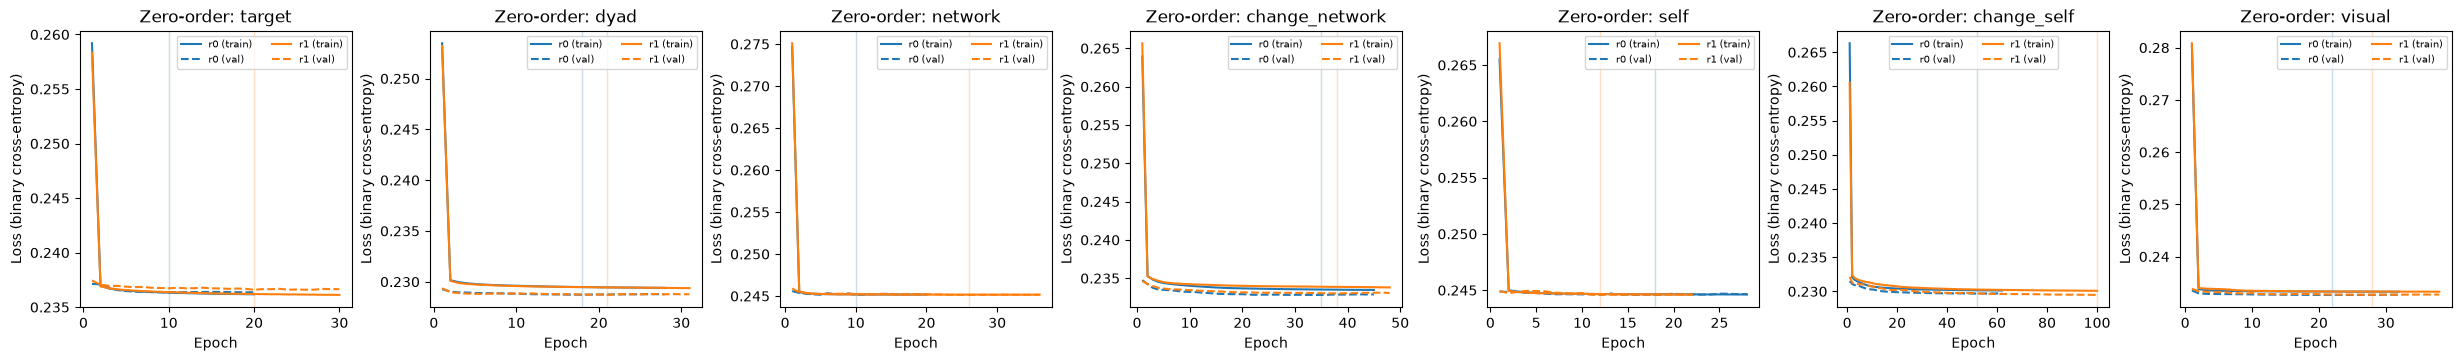

In [10]:
# ---------------------------------------------------------------------------
# Zero-order lesioned variants: each feature group modeled alone.
# Depth is still fixed at N_LAYERS (see build_model's docstring); width
# shrinks with the smaller input, which is not the same confound.
#
# One subplot per group (not one shared axes across groups) since these are
# different models with potentially different loss scales, not just repeats
# of the same model; within a subplot, its N_REPEATS fits share the axes.
# ---------------------------------------------------------------------------
fig_zo, axes_zo = plt.subplots(1, len(FEATURE_GROUPS),
                               figsize=(3.5 * len(FEATURE_GROUPS), 3.5),
                               constrained_layout=True)

zero_order_repeats = {}
for ax, g in zip(axes_zo, FEATURE_GROUPS):
    reps = [fit_and_score([g], seed=BASE_SEED + r, n_layers=N_LAYERS,
                          loss_ax=ax, label=f'r{r}')
            for r in range(N_REPEATS)]
    zero_order_repeats[g] = reps
    ax.set_title(f'Zero-order: {g}')
    mean_bss = pd.concat(reps, axis=1).mean(axis=1)
    print(f"zero-order [{g}]: mean participant Brier skill = {mean_bss.mean():.4f}")

zero_order_bss = pd.DataFrame({g: pd.concat(reps, axis=1).mean(axis=1)
                               for g, reps in zero_order_repeats.items()})

leave-one-out [-target]: mean Brier skill = 0.0530
leave-one-out [-dyad]: mean Brier skill = 0.0555
leave-one-out [-network]: mean Brier skill = 0.0557
leave-one-out [-change_network]: mean Brier skill = 0.0555
leave-one-out [-self]: mean Brier skill = 0.0550
leave-one-out [-change_self]: mean Brier skill = 0.0558
leave-one-out [-visual]: mean Brier skill = 0.0556

Unique contribution (complete - leave-one-out):
target            0.003192
dyad              0.000596
network           0.000448
change_network    0.000629
self              0.001110
change_self       0.000355
visual            0.000498
dtype: float64


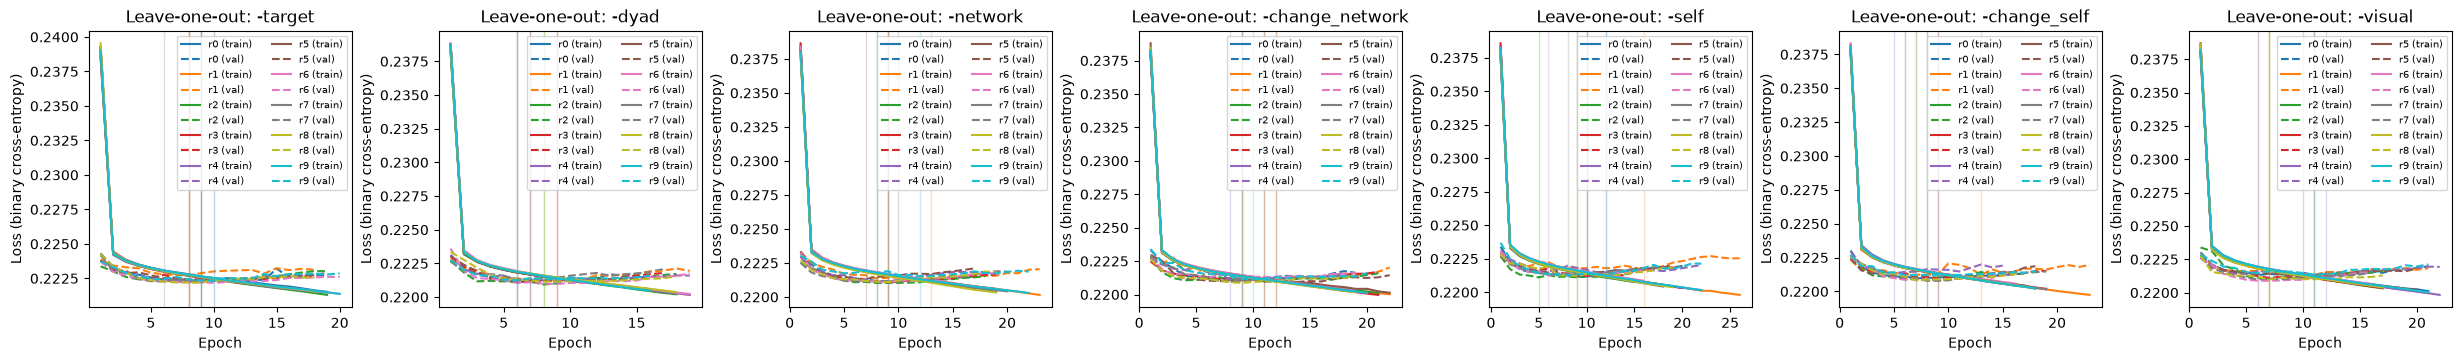

In [42]:
# ---------------------------------------------------------------------------
# Leave-one-group-out lesioned variants, and the unique contribution of
# each group: complete - leave_one_out.
#
# CHANGED: N_REPEATS_LOO=10, up from N_REPEATS=2. The repeat-reliability
# cell near the end of this notebook (run after an earlier pass with
# N_REPEATS=2 everywhere) showed `unique` was by far the least reliable
# quantity in the whole notebook -- several groups had between-repeat
# correlations below 0.4, a couple negative -- while `complete` itself was
# already ~0.996 reliable. Since unique[g] = complete - loo[g], and
# complete is already near-ceiling, the instability has to be coming from
# the individual leave-one-out fits, not from complete. Spearman-Brown
# projection from that reliability check suggested ~10 repeats gets most
# of the substantive groups (target, change_network, change_self, visual)
# into a reasonable (~0.7-0.9) range; `self` remains low even at 10 (it's
# a context group, so a near-zero true unique effect is plausible and no
# amount of averaging fixes that) -- see the discussion above that cell.
#
# CHANGED: average-then-diff instead of diff-then-average. The old
# diff-then-average approach (pair repeat r's complete fit with repeat r's
# leave-one-out fit, then average the paired differences) required equal
# repeat counts on both sides -- complete_repeats only has N_REPEATS=2
# entries, so pairing it against 10 leave-one-out repeats would index out
# of bounds. mean(a_r - b_r) == mean(a_r) - mean(b_r) exactly whenever the
# counts DO match (a basic property of averaging), so this doesn't change
# any of the old unique_bss values where it was still computed the old
# way -- it only changes how the two (now differently-sized) sides get
# combined. One real cost: this removes the paired per-repeat diffs that
# let the reliability check directly measure unique's own reliability: the
# meaningful diagnostic left is loo_repeats[g]'s own reliability (complete
# is separately known to be excellent), which the reliability cell now
# reports under type='loo' instead of type='unique'.
#
# One subplot per left-out group, same rationale as the zero-order cell.
# ---------------------------------------------------------------------------
N_REPEATS_LOO = 10

fig_loo, axes_loo = plt.subplots(1, len(FEATURE_GROUPS),
                                 figsize=(3.5 * len(FEATURE_GROUPS), 3.5),
                                 constrained_layout=True)

loo_repeats = {}
for ax, g in zip(axes_loo, FEATURE_GROUPS):
    reduced = [k for k in FEATURE_GROUPS if k != g]
    reps = [fit_and_score(reduced, seed=BASE_SEED + r, n_layers=N_LAYERS,
                          loss_ax=ax, label=f'r{r}')
            for r in range(N_REPEATS_LOO)]
    loo_repeats[g] = reps
    ax.set_title(f'Leave-one-out: -{g}')
    mean_bss = pd.concat(reps, axis=1).mean(axis=1)
    print(f"leave-one-out [-{g}]: mean Brier skill = {mean_bss.mean():.4f}")

loo_bss = pd.DataFrame({g: pd.concat(reps, axis=1).mean(axis=1) for g, reps in loo_repeats.items()})
unique_bss = pd.DataFrame({g: complete_bss - loo_bss[g] for g in loo_bss.columns})
print("\nUnique contribution (complete - leave-one-out):")
print(unique_bss.mean())


In [44]:
# ---------------------------------------------------------------------------
# Assemble results for inference: a tidy long-format table (one row per
# participant x group x {complete, zero_order, unique}), analogous to the
# zcoef/ucoef per-subject arrays in analyze_nets.R.
# ---------------------------------------------------------------------------
complete_long = complete_bss.reset_index()
complete_long.columns = ['sid', 'brier_skill']
complete_long['group'] = 'complete'
complete_long['type']  = 'complete'

zero_order_long = zero_order_bss.reset_index().melt(id_vars='sid', var_name='group', value_name='brier_skill')
zero_order_long['type'] = 'zero_order'

unique_long = unique_bss.reset_index().melt(id_vars='sid', var_name='group', value_name='brier_skill')
unique_long['type'] = 'unique'

results = pd.concat([complete_long, zero_order_long, unique_long], ignore_index=True)
results.groupby(['type', 'group'])['brier_skill'].describe()

count      mean       std       min       25%  \
type       group                                                            
complete   complete        1723.0  0.056144  0.098618 -0.142766 -0.027033   
unique     change_network  1723.0  0.000629  0.005091 -0.018218 -0.002720   
           change_self     1723.0  0.000355  0.005625 -0.020300 -0.003331   
           dyad            1723.0  0.000596  0.005627 -0.019021 -0.002859   
           network         1723.0  0.000448  0.006252 -0.020728 -0.003856   
           self            1723.0  0.001110  0.005732 -0.019376 -0.002807   
           target          1723.0  0.003192  0.009653 -0.023024 -0.003428   
           visual          1723.0  0.000498  0.005995 -0.019618 -0.003582   
zero_order change_network  1723.0  0.024737  0.049844 -0.083371 -0.014943   
           change_self     1723.0  0.035747  0.079391 -0.111784 -0.031325   
           dyad            1723.0  0.036546  0.083648 -0.116594 -0.033170   
           network         1723.0 -0.001547  0.000436 -0.003478 -0.001820   
           self            1723.0 -0.000354  0.000084 -0.000701 -0.000405   
           target          1723.0  0.018212  0.030699 -0.065166 -0.002865   
           visual          1723.0  0.025350  0.055201 -0.101514 -0.019304   

                                50%       75%       max  
type       group                                         
complete   complete        0.041464  0.142556  0.286187  
unique     change_network  0.000706  0.003822  0.017430  
           change_self     0.000236  0.003977  0.018728  
           dyad            0.000512  0.004126  0.020156  
           network         0.000211  0.004397  0.019713  
           self            0.000973  0.004882  0.023991  
           target          0.002368  0.009130  0.044931  
           visual          0.000119  0.004212  0.024237  
zero_order change_network  0.018887  0.066401  0.163081  
           change_self     0.022161  0.107617  0.218313  
           dyad            0.018928  0.109546  0.255104  
           network        -0.001500 -0.001229 -0.000648  
           self           -0.000345 -0.000294 -0.000142  
           target          0.015078  0.035857  0.126905  
           visual          0.020321  0.075429  0.140197

In [45]:
# ---------------------------------------------------------------------------
# Primary inferential tests:
#   - is the complete model better than chance? (single confirmatory test,
#     not part of the multiple-comparisons family below)
#   - is each group's zero-order Brier skill > 0? (predictive alone)
#   - is each group's unique contribution > 0? (predictive beyond the rest)
# The zero-order + unique tests (one pair per feature group, so the family
# size tracks len(FEATURE_GROUPS)*2) form one Holm-Bonferroni family,
# matching the zero-order/unique structure in analyze_nets.R.
#
# CHANGED: zero-order tests are now one-sided (alternative='greater').
# 'self'/'network' (the *_context groups) are built only on features that
# are constant within a trial (they don't vary across candidates), so by
# construction those models cannot discriminate which candidate was chosen
# and their Brier skill has no way to be reliably above 0 -- any reliable
# deviation from 0 is a systematic offset artifact (e.g. predicting the
# sample base rate instead of matching each trial's own 1/n_options chance
# reference), not evidence of genuinely bad (or good) predictive skill in a
# meaningful directional sense. A two-sided test flags a negative deviation
# as "significant" in a way that's misleading for exactly these two groups;
# one-sided (skill > 0 only) is the hypothesis that's actually meaningful
# for a zero-order test. Unique-contribution tests stay two-sided -- a
# leave-one-out model still varies within trial even when the left-out
# group doesn't, so a negative unique contribution is a real, interpretable
# result there, not a forced artifact.
# ---------------------------------------------------------------------------
def holm_adjust(pvals):
    p = np.asarray(pvals, dtype=float)
    n = len(p)
    order = np.argsort(p)
    adj = np.empty(n)
    running_max = 0.0
    for rank, idx in enumerate(order):
        val = min((n - rank) * p[idx], 1.0)
        running_max = max(running_max, val)
        adj[idx] = running_max
    return adj

def one_sample_tests(mat, kind, alternative='two-sided'):
    rows = []
    for g in mat.columns:
        x = mat[g].dropna()
        t = stats.ttest_1samp(x, 0, alternative=alternative)
        rows.append({'type': kind, 'group': g, 'mean': x.mean(),
                     't': t.statistic, 'p': t.pvalue, 'n': len(x), 'alternative': alternative})
    return pd.DataFrame(rows)

t_complete = stats.ttest_1samp(complete_bss.dropna(), 0)
complete_test = pd.DataFrame([{'type': 'complete', 'group': 'complete',
                               'mean': complete_bss.mean(), 't': t_complete.statistic,
                               'p': t_complete.pvalue, 'n': complete_bss.notna().sum()}])

ablation_tests = pd.concat([one_sample_tests(zero_order_bss, 'zero_order', alternative='greater'),
                            one_sample_tests(unique_bss, 'unique', alternative='two-sided')], ignore_index=True)
ablation_tests['p_holm'] = holm_adjust(ablation_tests['p'])

print("Complete model vs. chance:")
print(complete_test, "\n")
print(f"Zero-order (one-sided, skill>0) and unique (two-sided) contributions "
      f"(Holm-corrected within this family of {len(ablation_tests)}):")
print(ablation_tests)

Complete model vs. chance:
       type     group      mean          t              p     n
0  complete  complete  0.056144  23.631517  3.611407e-107  1723 

Zero-order (one-sided, skill>0) and unique (two-sided) contributions (Holm-corrected within this family of 14):
          type           group      mean           t              p     n  \
0   zero_order          target  0.018212   24.625161  2.900390e-115  1723   
1   zero_order            dyad  0.036546   18.135330   1.049770e-67  1723   
2   zero_order         network -0.001547 -147.369920   1.000000e+00  1723   
3   zero_order  change_network  0.024737   20.600747   9.058429e-85  1723   
4   zero_order            self -0.000354 -175.755942   1.000000e+00  1723   
5   zero_order     change_self  0.035747   18.690005   2.015958e-71  1723   
6   zero_order          visual  0.025350   19.061937   5.904612e-74  1723   
7       unique          target  0.003192   13.726740   9.047273e-41  1723   
8       unique            dyad  0.0005

In [46]:
# ---------------------------------------------------------------------------
# Secondary: pairwise comparisons between groups, within zero-order and
# within unique separately (each its own Holm family) -- mirrors the
# pairwise structure in analyze_nets.R.
# ---------------------------------------------------------------------------
def pairwise_tests(mat, kind):
    groups = list(mat.columns)
    rows = []
    for i in range(len(groups)):
        for j in range(i + 1, len(groups)):
            gi, gj = groups[i], groups[j]
            d = (mat[gi] - mat[gj]).dropna()
            t = stats.ttest_1samp(d, 0)
            rows.append({'type': kind, 'g1': gi, 'g2': gj,
                         'mean_diff': d.mean(), 't': t.statistic, 'p': t.pvalue, 'n': len(d)})
    out = pd.DataFrame(rows)
    out['p_holm'] = holm_adjust(out['p'])
    return out

zero_order_pairwise = pairwise_tests(zero_order_bss, 'zero_order')
unique_pairwise      = pairwise_tests(unique_bss, 'unique')

print("Zero-order pairwise comparisons:")
print(zero_order_pairwise, "\n")
print("Unique-contribution pairwise comparisons:")
print(unique_pairwise)

Zero-order pairwise comparisons:
          type              g1              g2  mean_diff           t  \
0   zero_order          target            dyad  -0.018333   -9.244424   
1   zero_order          target         network   0.019759   26.717745   
2   zero_order          target  change_network  -0.006525   -5.227462   
3   zero_order          target            self   0.018567   25.103841   
4   zero_order          target     change_self  -0.017534   -9.662166   
5   zero_order          target          visual  -0.007137   -5.570141   
6   zero_order            dyad         network   0.038092   18.904539   
7   zero_order            dyad  change_network   0.011809   12.981643   
8   zero_order            dyad            self   0.036900   18.310236   
9   zero_order            dyad     change_self   0.000799    1.951890   
10  zero_order            dyad          visual   0.011196   13.360380   
11  zero_order         network  change_network  -0.026284  -21.890379   
12  zero_order    

## Additional analyses: visual-baseline comparisons

Three follow-up analyses, motivated by the zero-order/unique split above:
almost every group is positive at zero-order, but only `target` survives as
a unique contribution once every other group is controlled for, and `dyad`/
`change_self` flip to significantly *negative* unique contributions. That
pattern is hard to interpret on its own -- it's consistent with those
groups' zero-order predictive power being partly redundant with something
else in the model, but the leave-one-out unique contribution doesn't say
*what* they're redundant with, or how much of the joint effect each group
is responsible for. These three analyses target that gap directly:

1. **Marginal benefit over visual alone** -- for each of the 6 non-visual
   groups, how much does adding *just that group* to a visual-only baseline
   improve prediction? Deliberately narrower than the full leave-one-out
   unique contribution (which controls for all 5 other groups at once): it
   isolates redundancy with the visual layout specifically, the one group
   we're confident is a pure confound rather than a substantive effect.
   Conservative in the same way the unique contributions are -- shared
   variance between a group and visual isn't necessarily *caused* by the
   visual confound -- but it's a more targeted question than the
   all-groups-at-once unique contribution.
2. **Complete vs. visual-only** -- the total gap between the full model
   (all 7 groups) and a visual-only baseline: the overall predictive value
   of every graph-theoretic feature combined, over and above visual layout.
   Free to compute -- both `complete_repeats` and
   `zero_order_repeats['visual']` already exist.
3. **Shapley decomposition of that gap** -- (2) split into exactly 6
   numbers, one per non-visual group, that sum to the total gap exactly.
   Computed exactly (all 2^6=64 subsets of the 6 groups, each combined with
   visual; refit only where not already cached from (1), the complete
   model, or the visual-only zero-order fit), rather than a single
   arbitrary add-one-group-at-a-time order, which would give a different
   (still-valid-looking) answer depending on which order the 6 groups
   happen to be added in. Reported per participant, so it inherits the
   same one-sample-test machinery as everything above.


visual+target: mean participant Brier skill = 0.0438
visual+dyad: mean participant Brier skill = 0.0450
visual+network: mean participant Brier skill = 0.0316
visual+change_network: mean participant Brier skill = 0.0354
visual+self: mean participant Brier skill = 0.0366
visual+change_self: mean participant Brier skill = 0.0410

Marginal benefit over visual alone:
target            0.018476
dyad              0.019662
network           0.006269
change_network    0.010067
self              0.011259
change_self       0.015655
dtype: float64


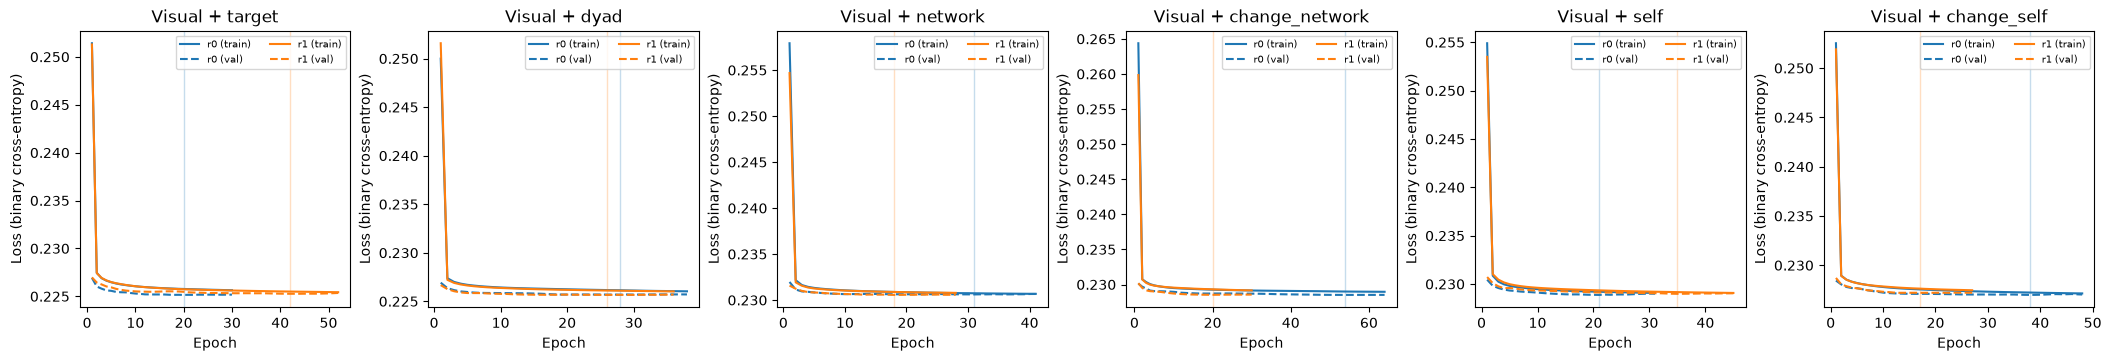

In [15]:
# ---------------------------------------------------------------------------
# Analysis 1: marginal benefit of each substantive group over visual alone.
#
# For each of the 6 non-visual groups, fit a 2-group model (visual + that
# group) and compare it to the visual-only zero-order fit already computed
# above -- paired by repeat (not by already-averaged means), the same way
# unique_bss pairs complete against leave-one-out, so each repeat's own
# fitting noise cancels in the subtraction instead of compounding across two
# independently-averaged estimates.
# ---------------------------------------------------------------------------
SUBSTANTIVE_GROUPS = [g for g in FEATURE_GROUPS if g != 'visual']

fig_marg, axes_marg = plt.subplots(1, len(SUBSTANTIVE_GROUPS),
                                   figsize=(3.5 * len(SUBSTANTIVE_GROUPS), 3.5),
                                   constrained_layout=True)

marginal_repeats = {}
for ax, g in zip(axes_marg, SUBSTANTIVE_GROUPS):
    reps = [fit_and_score(['visual', g], seed=BASE_SEED + r, n_layers=N_LAYERS,
                          loss_ax=ax, label=f'r{r}')
            for r in range(N_REPEATS)]
    marginal_repeats[g] = reps
    ax.set_title(f'Visual + {g}')
    mean_bss = pd.concat(reps, axis=1).mean(axis=1)
    print(f"visual+{g}: mean participant Brier skill = {mean_bss.mean():.4f}")

marginal_diffs = {g: [marginal_repeats[g][r] - zero_order_repeats['visual'][r] for r in range(N_REPEATS)]
                  for g in SUBSTANTIVE_GROUPS}
marginal_bss = pd.DataFrame({g: pd.concat(diffs, axis=1).mean(axis=1)
                             for g, diffs in marginal_diffs.items()})
print("\nMarginal benefit over visual alone:")
print(marginal_bss.mean())


In [16]:
# ---------------------------------------------------------------------------
# Analysis 2: complete model vs. visual-only zero-order -- the total
# predictive value of every graph-theoretic feature combined (including the
# network/self context groups), over and above the visual layout confound.
# No new fits: both complete_repeats (the complete-model cell) and
# zero_order_repeats['visual'] (the zero-order cell) already exist -- paired
# by repeat, same rationale as Analysis 1 and the existing unique_bss.
# ---------------------------------------------------------------------------
total_gap_diffs = [complete_repeats[r] - zero_order_repeats['visual'][r] for r in range(N_REPEATS)]
total_gap_bss = pd.concat(total_gap_diffs, axis=1).mean(axis=1).rename('total_gap')
print(f"Complete vs. visual-only: mean total gap in participant Brier skill = {total_gap_bss.mean():.4f}")


Complete vs. visual-only: mean total gap in participant Brier skill = 0.0308


In [17]:
# ---------------------------------------------------------------------------
# Analysis 3a: exact Shapley decomposition -- fit every subset of the 6
# substantive groups (each combined with visual) needed to compute it.
#
# There are 2^6 = 64 subsets of SUBSTANTIVE_GROUPS. Three "corners" are
# already cached from earlier cells: the empty subset (visual alone, from
# the zero-order cell), the full subset (all 6, = the complete model), and
# each of the 6 singletons (from Analysis 1's marginal-benefit fits). That
# leaves 64 - 1 - 1 - 6 = 56 new subsets to fit, each N_REPEATS times = 112
# new fits -- roughly 4x everything fit in the cells above combined.
#
# plot_loss is off for this bulk enumeration (56 subplots of training
# curves would be unreadable clutter, not a useful sanity check) -- the
# "corner" fits already plotted their curves in their own cells above.
# ---------------------------------------------------------------------------
from itertools import combinations, chain

ALL_SUBSETS = list(chain.from_iterable(
    combinations(SUBSTANTIVE_GROUPS, k) for k in range(len(SUBSTANTIVE_GROUPS) + 1)))
print(f"total subsets: {len(ALL_SUBSETS)}")

subset_repeats = {frozenset(): zero_order_repeats['visual'],
                  frozenset(SUBSTANTIVE_GROUPS): complete_repeats}
for g in SUBSTANTIVE_GROUPS:
    subset_repeats[frozenset([g])] = marginal_repeats[g]

n_new = 0
for S in ALL_SUBSETS:
    key = frozenset(S)
    if key in subset_repeats:
        continue
    active_groups = ['visual'] + list(S)
    subset_repeats[key] = [fit_and_score(active_groups, seed=BASE_SEED + r, n_layers=N_LAYERS,
                                         plot_loss=False)
                           for r in range(N_REPEATS)]
    n_new += N_REPEATS
    if n_new % (10 * N_REPEATS) == 0:
        print(f"  ... {n_new} new fits done")

print(f"new fits required: {n_new} (expected {56 * N_REPEATS})")
assert n_new == 56 * N_REPEATS
assert len(subset_repeats) == 2 ** len(SUBSTANTIVE_GROUPS)


total subsets: 64
  ... 20 new fits done
  ... 40 new fits done
  ... 60 new fits done
  ... 80 new fits done
  ... 100 new fits done
new fits required: 112 (expected 112)


In [18]:
# ---------------------------------------------------------------------------
# Analysis 3b: Shapley values from the cached subset fits above.
#
# phi_g = sum over subsets S of (SUBSTANTIVE_GROUPS \ {g}) of
#         [|S|! * (n-|S|-1)!] / n! * (v(S U {g}) - v(S))
# -- the average marginal contribution of g across every possible order in
# which the 6 groups could be added, computed exactly (not sampled) since
# n=6 keeps the full 2^6 enumeration cheap. Computed per repeat (v(S) is
# that repeat's per-participant Brier skill for the visual+S model), then
# averaged across repeats -- same paired-by-repeat logic as everywhere else
# in this notebook.
#
# The defining ("efficiency") property of Shapley values is that they sum
# EXACTLY to v(full) - v(empty) = total_gap_bss from Analysis 2 -- checked
# below per participant, not just on average, as a correctness check on the
# implementation itself (not merely a property we hope holds).
# ---------------------------------------------------------------------------
from math import factorial

def shapley_values(groups, v):
    """v: dict frozenset(subset of `groups`) -> per-participant pd.Series."""
    n = len(groups)
    phi = {g: 0 for g in groups}
    for g in groups:
        others = [x for x in groups if x != g]
        for k in range(len(others) + 1):
            weight = factorial(k) * factorial(n - k - 1) / factorial(n)
            for S in combinations(others, k):
                S = frozenset(S)
                phi[g] = phi[g] + weight * (v[S | {g}] - v[S])
    return phi

shapley_repeats = []
for r in range(N_REPEATS):
    v_r = {S: subset_repeats[S][r] for S in subset_repeats}
    shapley_repeats.append(shapley_values(SUBSTANTIVE_GROUPS, v_r))

shapley_bss = pd.DataFrame({g: pd.concat([shapley_repeats[r][g] for r in range(N_REPEATS)], axis=1).mean(axis=1)
                            for g in SUBSTANTIVE_GROUPS})

efficiency_gap = (shapley_bss.sum(axis=1) - total_gap_bss).abs().max()
print(f"max |sum(Shapley shares) - total_gap| across participants: {efficiency_gap:.2e}")
assert efficiency_gap < 1e-8, "Shapley efficiency axiom violated -- bug in the implementation"

print("\nShapley decomposition of the complete-vs-visual gap:")
print(shapley_bss.mean())


max |sum(Shapley shares) - total_gap| across participants: 2.78e-17

Shapley decomposition of the complete-vs-visual gap:
target            0.007959
dyad              0.007480
network           0.001774
change_network    0.003174
self              0.004662
change_self       0.005745
dtype: float64


## Repeat-to-repeat reliability

For every fitted quantity above: the between-repeat Pearson correlation
(across participants), averaged over every pair of repeats (a single value
when there are only 2; the mean of `C(N,2)` pairwise correlations for
`loo`, which now has `N_REPEATS_LOO=10`). A value near 1 means the repeats
agree closely per participant -- averaging is mostly smoothing small,
idiosyncratic noise. A low value means the repeats disagree substantially
per participant -- more repeats help, but only up to a point (a
near-zero true effect, as expected for the context groups, stays
unreliable no matter how many repeats you average).

`unique` itself isn't listed separately: since it's now computed as
`complete_bss - loo_bss[g]` (average-then-diff, needed because `complete`
and the lesioned fits no longer share a repeat count -- see the
leave-one-out cell), there's no per-repeat *unique* series left to check.
`loo`'s own reliability is the informative diagnostic instead --
`complete`'s reliability is tracked separately and was already ~0.996 at
just 2 repeats, so it isn't the bottleneck.


In [47]:
# ---------------------------------------------------------------------------
# Repeat-to-repeat reliability for every quantity fitted above.
# ---------------------------------------------------------------------------
def repeat_reliability(reps):
    """reps: list of per-repeat, per-participant pd.Series. Returns the
    mean pairwise Pearson correlation across all C(len(reps), 2) repeat
    pairs (a single correlation when len(reps) == 2)."""
    if len(reps) < 2:
        return np.nan
    mat = pd.concat(reps, axis=1)
    mat.columns = range(len(reps))
    corr = mat.corr()
    pairs = [(i, j) for i in range(len(reps)) for j in range(i + 1, len(reps))]
    return np.mean([corr.iloc[i, j] for i, j in pairs])

reliability_rows = [
    {'type': 'complete', 'group': 'complete', 'n_repeats': len(complete_repeats),
     'repeat_r': repeat_reliability(complete_repeats)},
]
for g in FEATURE_GROUPS:
    reliability_rows.append({'type': 'zero_order', 'group': g, 'n_repeats': len(zero_order_repeats[g]),
                             'repeat_r': repeat_reliability(zero_order_repeats[g])})
for g in FEATURE_GROUPS:
    reliability_rows.append({'type': 'loo', 'group': g, 'n_repeats': len(loo_repeats[g]),
                             'repeat_r': repeat_reliability(loo_repeats[g])})
for g in SUBSTANTIVE_GROUPS:
    reliability_rows.append({'type': 'marginal', 'group': g, 'n_repeats': len(marginal_diffs[g]),
                             'repeat_r': repeat_reliability(marginal_diffs[g])})
reliability_rows.append({'type': 'total_gap', 'group': 'complete_vs_visual', 'n_repeats': len(total_gap_diffs),
                         'repeat_r': repeat_reliability(total_gap_diffs)})
for g in SUBSTANTIVE_GROUPS:
    reliability_rows.append({'type': 'shapley', 'group': g, 'n_repeats': N_REPEATS,
                             'repeat_r': repeat_reliability([shapley_repeats[r][g] for r in range(N_REPEATS)])})

reliability_df = pd.DataFrame(reliability_rows)
print("Repeat-to-repeat reliability (Pearson r across participants), worst first:")
print(reliability_df.sort_values('repeat_r').to_string(index=False))

low = reliability_df[reliability_df['repeat_r'] < 0.9]
if len(low):
    print(f"\n{len(low)} of {len(reliability_df)} quantities have repeat reliability < 0.9:")
    print(low.sort_values('repeat_r').to_string(index=False))
else:
    print("\nAll quantities have repeat reliability >= 0.9.")


Repeat-to-repeat reliability (Pearson r across participants), worst first:
      type              group  n_repeats  repeat_r
zero_order               self          2  0.409268
   shapley            network          2  0.678546
  marginal            network          2  0.887375
   shapley     change_network          2  0.920211
  marginal     change_network          2  0.932640
  marginal               self          2  0.938656
   shapley        change_self          2  0.942132
   shapley             target          2  0.949087
   shapley               self          2  0.952599
zero_order            network          2  0.952651
  marginal             target          2  0.956134
  marginal        change_self          2  0.965158
 total_gap complete_vs_visual          2  0.979304
  marginal               dyad          2  0.984456
   shapley               dyad          2  0.987849
zero_order             target          2  0.989000
zero_order     change_network          2  0.994212
       

In [19]:
# ---------------------------------------------------------------------------
# Inferential tests for Analyses 1-3, following the same pattern as the
# complete-model/ablation tests above: Analysis 2's single comparison is a
# confirmatory test on its own (like complete vs. chance), while Analyses 1
# and 3 each form their own Holm-Bonferroni family (6 tests apiece,
# two-sided -- a group's marginal/Shapley contribution could plausibly go
# either way, unlike the one-sided zero-order tests for network/self).
# ---------------------------------------------------------------------------
t_total_gap = stats.ttest_1samp(total_gap_bss.dropna(), 0)
total_gap_test = pd.DataFrame([{'type': 'total_gap', 'group': 'complete_vs_visual',
                                'mean': total_gap_bss.mean(), 't': t_total_gap.statistic,
                                'p': t_total_gap.pvalue, 'n': total_gap_bss.notna().sum()}])

marginal_tests = one_sample_tests(marginal_bss, 'marginal', alternative='two-sided')
marginal_tests['p_holm'] = holm_adjust(marginal_tests['p'])

shapley_tests = one_sample_tests(shapley_bss, 'shapley', alternative='two-sided')
shapley_tests['p_holm'] = holm_adjust(shapley_tests['p'])

print("Complete vs. visual-only (single confirmatory test):")
print(total_gap_test, "\n")
print(f"Marginal benefit over visual (two-sided, Holm-corrected within this family of {len(marginal_tests)}):")
print(marginal_tests, "\n")
print(f"Shapley decomposition (two-sided, Holm-corrected within this family of {len(shapley_tests)}):")
print(shapley_tests)


Complete vs. visual-only (single confirmatory test):
        type               group      mean          t              p     n
0  total_gap  complete_vs_visual  0.030794  26.122436  5.461610e-127  1723 

Marginal benefit over visual (two-sided, Holm-corrected within this family of 6):
       type           group      mean          t              p     n  \
0  marginal          target  0.018476  32.260796  5.292520e-179  1723   
1  marginal            dyad  0.019662  20.634265   1.039478e-84  1723   
2  marginal         network  0.006269  22.380810   1.358181e-97  1723   
3  marginal  change_network  0.010067  26.712941  8.119426e-132  1723   
4  marginal            self  0.011259  25.882161  4.881293e-125  1723   
5  marginal     change_self  0.015655  21.259604   2.972237e-89  1723   

  alternative         p_holm  
0   two-sided  3.175512e-178  
1   two-sided   1.039478e-84  
2   two-sided   4.074542e-97  
3   two-sided  4.059713e-131  
4   two-sided  1.952517e-124  
5   two-sided  

## Visualization (ported from `analyze_nets.R`'s `combined_regression.pdf`)

One row per feature group (we're plotting group-level Brier skill, not
per-predictor regression coefficients), in a 2x2 grid of panels: **A**
zero-order ("Full") and **B** unique (leave-one-out) on top; **C** marginal
benefit over visual alone (Analysis 1) and **D** Shapley share of the
complete-vs-visual gap (Analysis 3) on the bottom. Dark shade for the one
unconditional ("raw") panel (A); light shade for the three
conditional/partial ones (B, C, D), which all answer some version of "how
much does this group add, given something else is already accounted for" --
just with a different "something else" each time (all other groups; visual
alone; a fair share of the joint effect, respectively).

**CHANGED (layout)**: four panels arranged 2x2 instead of 1x4 -- each row of
the grid (A+B, then C+D) gets its own shared label column on the left, its
own header row, and its own x-axis, exactly mirroring what a single 1x4 row
used to do, just wrapped after 2 panels instead of 4. `visual` has no
marginal-benefit-over-itself or Shapley share of itself (it's the baseline
those two panels are computed relative to), so panels C and D draw a blank
"(baseline)" placeholder in `visual`'s row instead of omitting the row --
keeps all four panels' rows aligned to their row-group's shared label
column. That placeholder text sits to the right of center (not centered),
so it doesn't sit on top of the dashed zero-reference line; the row still
carries a real x-axis (ticks + "Brier skill score" label), matching every
other row's bottom axis -- an earlier version of this figure blanked the
whole row (`axis('off')` on both sub-axes), which silently deleted C/D's
x-axis along with it, since `visual` is always the last row.

**Update**: `change` is split into `change_network`/`change_self` (see the
registry cell) to match `analyze_nets.R`'s category structure, where
"Network" and "Self" *are* the change variables. We settled on seven fully
distinct hues, one per group, from matplotlib's `tab20` palette (the same
Vega/D3 category20 set as R's `RColorBrewer::brewer.pal(..., "Paired")`
lineage, just a different concrete list) instead of two shades of one hue
per family, since context and change no longer need to visually relate to
each other at all. `target`, `dyad`, `change_network`, and `change_self` use
the exact same hex values as `analyze_nets.R`'s `catcol_dark`/`catcol_light`
(green/orange/purple/blue) -- after that script's context-exclusion
refactor, its "Network"/"Self" categories *are* these change-only groups
(context baselines are excluded from R's analysis entirely and analyzed
here instead, in `network`/`self`, which get their own pink/teal hues since
R has no equivalent group to match against). `visual` bundles every
layout-derived feature into one group, colored with tab20's brown pair --
`analyze_nets.R` keeps these folded into their original target/dyad hues
instead, since it doesn't run this group-level ablation.

- the per-row group label is centered in its row-group's shared left
  column, vertically aligned to the line between each row's histogram and
  boxplot (not the row's overall center).
- bare "A"/"B"/"C"/"D" panel letters mark the four panels, left-aligned at
  the same height as that panel's own header (not below it, in the
  panel's own top-left corner as in an earlier version).
- no figure-level title.
- `visual` is always the last (bottom) row in every panel, regardless of
  its own effect size -- it isn't part of any target/dyad/network/self
  family, so it has nothing to be sorted relative to.


In [48]:
# ---------------------------------------------------------------------------
# Colors: matplotlib's tab20 (Vega/D3 category20). target/dyad/change_network/
# change_self use the exact same hex pairs as analyze_nets.R's
# catcol_dark/catcol_light (green/orange/purple/blue) -- after that script's
# context-exclusion refactor, its "Network"/"Self" categories *are* these
# change-in-network/change-in-self groups (context baselines are excluded
# from R's analysis entirely, analyzed here instead). network/self (the
# *_context groups) get their own additional pink/teal hues since R has no
# equivalent group to match colors with. visual bundles every layout-derived
# feature (vdist, vecc, uvecc) into one group, colored with tab20's brown
# pair -- R keeps these folded into their original target/dyad hues rather
# than singling them out, since R doesn't run this group-level ablation.
# ---------------------------------------------------------------------------
GROUP_COLOR_DARK = {
    'target':         '#2CA02C',   # tab20 green   -- == analyze_nets.R catcol_dark[Target]
    'dyad':           '#FF7F0E',   # tab20 orange  -- == analyze_nets.R catcol_dark[Dyad]
    'network':        '#E377C2',   # tab20 pink      -- Network (context)
    'change_network': '#9467BD',   # tab20 purple  -- == analyze_nets.R catcol_dark[Network]
    'self':           '#17BECF',   # tab20 teal/cyan -- Self (context)
    'change_self':    '#1F77B4',   # tab20 blue    -- == analyze_nets.R catcol_dark[Self]
    'visual':         '#8C564B',   # tab20 brown -- Visual (layout-derived)   ADDED
}
GROUP_COLOR_LIGHT = {
    'target':         '#98DF8A',
    'dyad':           '#FFBB78',
    'network':        '#F7B6D2',
    'change_network': '#C5B0D5',
    'self':           '#9EDAE5',
    'change_self':    '#AEC7E8',
    'visual':         '#C49C94',   # ADDED
}
GROUP_LABELS = {
    'target':         'Target',
    'dyad':           'Dyad',
    'network':        'Network (context)',
    'change_network': 'Network (change)',
    'self':           'Self (context)',
    'change_self':    'Self (change)',
    'visual':         'Visual',   # ADDED
}

def group_family(g):
    """'change_X' is the change-counterpart of 'X' -- used only for row
    ordering now (see _ordered_groups), not for color (each group has its
    own direct color entry above). 'visual' has no counterpart and is never
    passed through here (_ordered_groups excludes it from family grouping
    entirely)."""
    return g[len('change_'):] if g.startswith('change_') else g

def is_change_group(g):
    return g.startswith('change_')

def group_label(g, labels=GROUP_LABELS):
    return labels[g]


In [49]:
def _ordered_groups(zero_order_bss, feature_groups):
    """Row order: families (target, dyad, network, self) ranked by their
    baseline zero-order mean (descending); within a family, the baseline
    group first, its change_* counterpart directly below it. Keeps a
    baseline group and its change counterpart adjacent (they're the two
    related colors of one family) instead of a flat sort-by-magnitude
    scattering them apart.

    'visual' is excluded from the family-based ranking and always appended
    last -- it has no baseline/change counterpart to pair with, and it's
    the reference/baseline group for Analyses 1 and 3 (marginal benefit and
    Shapley share), so it belongs at the bottom of every panel regardless
    of its own effect size.
    """
    means = zero_order_bss.mean()
    families = {}
    for g in feature_groups:
        if g == 'visual':
            continue
        families.setdefault(group_family(g), []).append(g)

    def family_key(fam):
        baseline = [g for g in families[fam] if not is_change_group(g)]
        ref = baseline if baseline else families[fam]
        return max(means[g] for g in ref)

    order = []
    for fam in sorted(families, key=family_key, reverse=True):
        order.extend(sorted(families[fam], key=is_change_group))  # baseline (False) before change (True)
    if 'visual' in feature_groups:
        order.append('visual')
    return order


def star(p):
    """Same thresholds/symbols as analyze_nets.R's star()."""
    if p is None or (isinstance(p, float) and np.isnan(p)):
        return ''
    if p < .001:
        return '***'
    if p < .01:
        return '**'
    if p < .05:
        return '*'
    return ''


def plot_group_results(panels, order, labels=GROUP_LABELS, n_cols=2, figsize=(13, 13),
                       txt_fontsize=10, savepath=None):
    """2x2 (or n_cols-wide) grid adaptation of analyze_nets.R's
    combined_regression.pdf for group-level Brier skill instead of
    per-predictor regression coefficients.

    `panels` is a flat list (one dict per panel, in row-major order -- A,
    B, C, D), wrapped into chunks of `n_cols` panels per row-group. Each
    row-group gets its own shared label column, header row, and x-axis,
    stacked vertically -- CHANGED from the earlier all-in-one-row (1x4)
    version, which no longer fit comfortably once there were four panels.

    Each panel dict has keys:
        data:      DataFrame, columns = group names. A group in `order`
                   missing from this panel's columns (e.g. 'visual' in the
                   marginal/Shapley panels, which are defined relative to
                   visual and so don't have a value *for* visual) is drawn
                   as a blank "(baseline)" placeholder row instead of being
                   omitted -- every panel keeps the same N rows so the
                   shared label column stays aligned across its row-group.
        color:     dict group -> hex, dark or light shade depending on
                   whether this panel is unconditional (zero-order, dark)
                   or conditional/partial (unique, marginal, Shapley --
                   light).
        letter:    panel letter ('A', 'B', ...), drawn left-aligned at the
                   same height as this panel's header (mirrors
                   analyze_nets.R's panel_letter(), adapted to sit level
                   with the title instead of inside the plot area).
        header:    descriptive header text, centered above the panel.
        sig_table: optional DataFrame with columns group/mean/p_holm (a
                   type-filtered slice of one of the ablation-test tables);
                   draws a significance asterisk (analyze_nets.R's star()
                   thresholds) near each histogram's tail, on the side
                   matching the mean's sign. None skips stars for that
                   panel.
        border:    box border color (grayscale string, matching
                   analyze_nets.R's grey40/grey75 -- matplotlib doesn't
                   understand R's "greyNN" names, so these are NN/100 as
                   plain floats instead).

    order: row order (e.g. from _ordered_groups(zero_order_bss,
        FEATURE_GROUPS)) -- computed once by the caller and shared across
        every panel and every row-group, rather than recomputed per panel,
        so a group's row lands in the exact same vertical position
        everywhere.
    """
    n = len(order)
    n_groups = -(-len(panels) // n_cols)   # ceil: number of row-groups

    fig = plt.figure(figsize=figsize)
    fig.canvas.draw()   # so the renderer below can measure real text extents
    renderer = fig.canvas.get_renderer()

    # ---- label column width: measured from the widest group label at
    # txt_fontsize (mirrors analyze_nets.R's lab_mid_in, measured via
    # strwidth() on a throwaway device, rather than a hardcoded guess) --
    # shared by every row-group, since they all show the same `order`. ----
    tmp_ax = fig.add_axes([0, 0, 1, 1])
    tmp_ax.set_visible(False)
    widths_in = []
    for g in order:
        txt = tmp_ax.text(0, 0, group_label(g, labels), fontsize=txt_fontsize)
        widths_in.append(txt.get_window_extent(renderer=renderer).width / fig.dpi)
        txt.remove()
    tmp_ax.remove()
    lab_w_in = max(widths_in) + 0.12   # small symmetric pad

    HEIGHT_RATIOS = [2.2, 1]   # hist : box, within each row
    hist_frac = HEIGHT_RATIOS[0] / sum(HEIGHT_RATIOS)   # fraction of row height that is the histogram

    outer_left, outer_right = 0.05, 0.99
    outer_top, outer_bottom = 0.96, 0.05
    row_group_gap = 0.08   # vertical gap between row-groups, in figure fraction
    row_group_h = (outer_top - outer_bottom - row_group_gap * (n_groups - 1)) / n_groups
    header_frac = 0.10     # fraction of a row-group's own height reserved for its header/letter

    usable_in = figsize[0] * (outer_right - outer_left)

    for rg in range(n_groups):
        rg_panels = panels[rg * n_cols:(rg + 1) * n_cols]
        n_this = len(rg_panels)

        rg_top = outer_top - rg * (row_group_h + row_group_gap)
        rg_bottom = rg_top - row_group_h
        grid_top = rg_top - header_frac * row_group_h
        grid_bottom = rg_bottom
        # same height for the header text and the panel letter, per request
        header_y = rg_top - 0.4 * header_frac * row_group_h

        side_w_in = (usable_in - lab_w_in) / n_this
        assert side_w_in > 0.8, (
            f"label column ({lab_w_in:.2f}in) leaves too little room for {n_this} "
            f"panels ({side_w_in:.2f}in each) -- widen figsize")

        width_ratios = [lab_w_in] + [side_w_in] * n_this
        row_gs = gridspec.GridSpec(1, n_this + 1, figure=fig, width_ratios=width_ratios,
                                   wspace=0, left=outer_left, right=outer_right,
                                   top=grid_top, bottom=grid_bottom)

        # ---- this row-group's own shared label column ----
        mid_rows = gridspec.GridSpecFromSubplotSpec(n, 1, subplot_spec=row_gs[0], hspace=0.60)
        for i, g in enumerate(order):
            ax_lab = fig.add_subplot(mid_rows[i])
            ax_lab.axis('off')
            ax_lab.text(1.0, 1 - hist_frac, group_label(g, labels), fontsize=txt_fontsize,
                       ha='right', va='center', transform=ax_lab.transAxes)

        for pi, spec in enumerate(rg_panels):
            cell = row_gs[pi + 1]
            mat = spec['data']
            colors = spec['color']
            sig_table = spec.get('sig_table')
            border = spec.get('border', '0.5')

            group_rows = gridspec.GridSpecFromSubplotSpec(n, 1, subplot_spec=cell, hspace=0.60)

            present_cols = [g for g in order if g in mat.columns]
            xmax = np.nanmax(np.abs(mat[present_cols].to_numpy())) * 1.15
            xmax = max(xmax, 1e-6)
            pad = 0.03 * xmax

            ax_h_first = None
            ax_b_last = None

            for i, g in enumerate(order):
                hist_box = gridspec.GridSpecFromSubplotSpec(
                    2, 1, subplot_spec=group_rows[i], height_ratios=HEIGHT_RATIOS, hspace=0)
                ax_h = fig.add_subplot(hist_box[0])
                ax_b = fig.add_subplot(hist_box[1])

                if g not in mat.columns:
                    # blank placeholder row -- e.g. 'visual' has no
                    # marginal-benefit-over-itself / Shapley share, but
                    # every panel still needs the same N rows so the
                    # shared label column stays aligned.
                    ax_h.set_xlim(-xmax, xmax)
                    ax_h.axis('off')
                    # shifted right of center so it doesn't sit on top of
                    # the dashed zero-reference line below.
                    ax_h.text(0.68, 0.5, '(baseline)', transform=ax_h.transAxes, ha='left',
                              va='center', fontsize=txt_fontsize - 1, color='0.6', style='italic')
                    # this row still carries the panel's shared x-axis (it's
                    # always the last row) -- only its y-decorations are
                    # hidden, not axis('off') wholesale, which used to
                    # delete the x-axis along with everything else.
                    ax_b.set_xlim(-xmax, xmax)
                    ax_b.set_yticks([])
                    for spine in ax_b.spines.values():
                        spine.set_visible(False)
                    if i == n - 1:
                        ax_b.set_xlabel('Brier skill score', fontsize=txt_fontsize)
                    else:
                        ax_b.set_xticks([])
                    if ax_h_first is None:
                        ax_h_first = ax_h
                    ax_b_last = ax_b
                    continue

                x = mat[g].dropna().to_numpy()
                col = colors[g]
                counts, _, _ = ax_h.hist(x, bins=60, range=(-xmax, xmax), density=True,
                                         color=col, edgecolor='white', linewidth=0.2)
                ax_h.set_xlim(-xmax, xmax)
                ax_h.axis('off')

                if sig_table is not None:   # significance asterisks, parallel analyze_nets.R's zpsym/upsym
                    row = sig_table[sig_table['group'] == g]
                    if len(row):
                        lab = star(row['p_holm'].iloc[0])
                        if lab:
                            ypos = counts.max() / 2 if len(counts) else 0
                            if row['mean'].iloc[0] > 0:
                                ax_h.text(np.quantile(x, 0.975) + pad, ypos, lab, fontsize=txt_fontsize, ha='left', va='center')
                            else:
                                ax_h.text(np.quantile(x, 0.025) - pad, ypos, lab, fontsize=txt_fontsize, ha='right', va='center')

                if ax_h_first is None:
                    ax_h_first = ax_h

                bp = ax_b.boxplot(x, vert=False, widths=0.8, notch=True,
                                  patch_artist=True, medianprops=dict(color='black'),
                                  flierprops=dict(marker='o', markersize=2,
                                                  markerfacecolor='black',
                                                  markeredgecolor='black'))
                for box in bp['boxes']:
                    box.set_facecolor(col)
                    box.set_edgecolor(border)
                ax_b.set_xlim(-xmax, xmax)
                ax_b.set_yticks([])
                for spine in ax_b.spines.values():
                    spine.set_visible(False)
                if i == n - 1:
                    ax_b.set_xlabel('Brier skill score', fontsize=txt_fontsize)
                else:
                    ax_b.set_xticks([])
                ax_b_last = ax_b

            # one dashed zero-reference line spanning every row in this
            # panel (top of the first histogram to the bottom of the last
            # box), instead of a short axvline repeated in each subplot --
            # drawn in figure coordinates since it crosses several
            # independent Axes.
            x_disp = ax_h_first.transData.transform((0, 0))[0]
            x_fig = fig.transFigure.inverted().transform((x_disp, 0))[0]
            y_top = ax_h_first.get_position().y1
            y_bottom = ax_b_last.get_position().y0
            fig.add_artist(Line2D([x_fig, x_fig], [y_bottom, y_top], transform=fig.transFigure,
                                  color='black', alpha=0.7, linewidth=1.5, linestyle='--'))

            pos = cell.get_position(fig)
            fig.text((pos.x0 + pos.x1) / 2, header_y, spec['header'], ha='center',
                     fontsize=txt_fontsize, fontweight='bold', va='center')
            # CHANGED: moved up to the same height as the header (was lower,
            # at the panel's own top-left corner) and still left-aligned --
            # "in the corner" of the panel, level with its title.
            fig.text(pos.x0 + 0.004, header_y, spec['letter'], ha='left', va='center',
                     fontsize=txt_fontsize, fontweight='bold')

    if savepath:
        fig.savefig(savepath)
    return fig


C:\Users\mthor\AppData\Local\Temp\ipykernel_40484\824682995.py:227: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax_b.boxplot(x, vert=False, widths=0.8, notch=True,
C:\Users\mthor\AppData\Local\Temp\ipykernel_40484\824682995.py:227: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax_b.boxplot(x, vert=False, widths=0.8, notch=True,
C:\Users\mthor\AppData\Local\Temp\ipykernel_40484\824682995.py:227: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax_b.boxplot(x, vert=False, widths=0.8, notch=True,
C:\Users\mthor\AppData\Local\Temp\ipykernel_40484\824682995.py:227: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and w

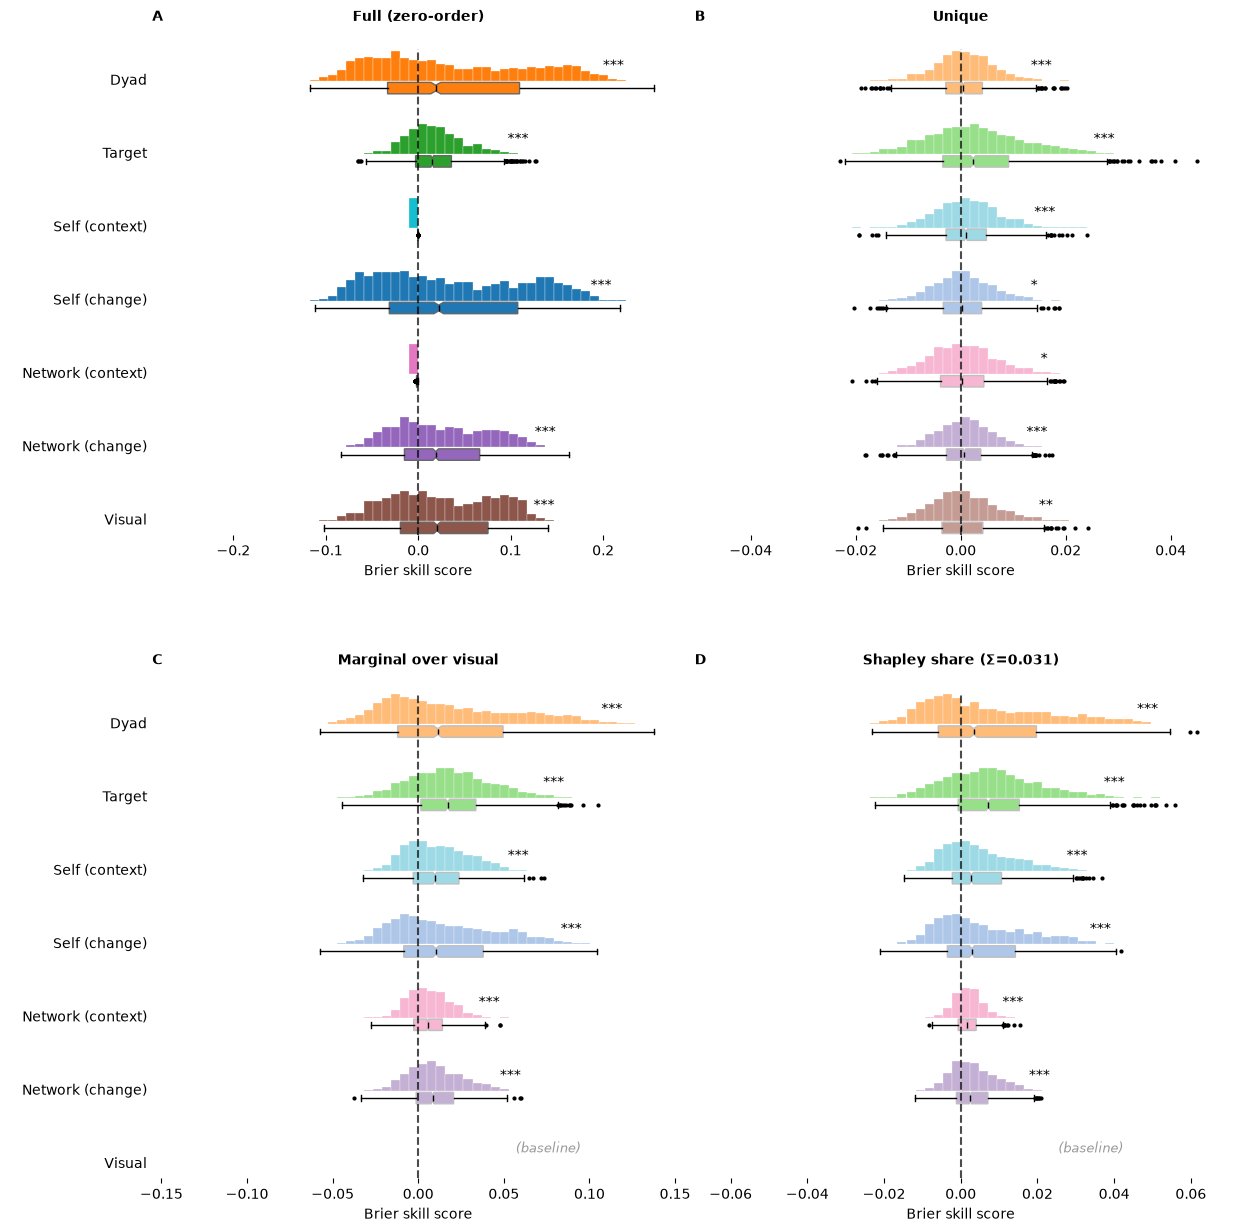

In [50]:
# ---------------------------------------------------------------------------
# Real visualization of the ablation results: four panels in a 2x2 grid --
# A zero-order, B unique (leave-one-out) on top; C marginal benefit over
# visual (Analysis 1), D Shapley share of the complete-vs-visual gap
# (Analysis 3) on the bottom. Analysis 2 (the total gap itself) isn't a
# per-group row and doesn't fit this layout -- its value is folded into
# panel D's header instead, next to the shares that sum to it.
# ---------------------------------------------------------------------------
order = _ordered_groups(zero_order_bss, FEATURE_GROUPS)

panels = [
    dict(data=zero_order_bss, color=GROUP_COLOR_DARK, letter='A',
         header='Full (zero-order)', sig_table=ablation_tests[ablation_tests['type'] == 'zero_order'],
         border='0.4'),
    dict(data=unique_bss, color=GROUP_COLOR_LIGHT, letter='B',
         header='Unique', sig_table=ablation_tests[ablation_tests['type'] == 'unique'],
         border='0.75'),
    dict(data=marginal_bss, color=GROUP_COLOR_LIGHT, letter='C',
         header='Marginal over visual', sig_table=marginal_tests,
         border='0.75'),
    dict(data=shapley_bss, color=GROUP_COLOR_LIGHT, letter='D',
         header=f'Shapley share (\u03a3={total_gap_bss.mean():.3f})', sig_table=shapley_tests,
         border='0.75'),
]

plot_group_results(panels, order, savepath='combined_brier_skill.pdf')
plt.show()


## Caching results

Everything above this point -- especially Analysis 3's 112 extra fits --
takes a long time to rerun. This saves the per-participant results and test
tables that the plotting/inference cells actually consume (not the fitted
models themselves, and not the feature data) to one `.npz` file, and
provides a loader that restores them without rerunning anything above.


In [51]:
# ---------------------------------------------------------------------------
# Save the key per-participant results and test tables to disk, so this
# notebook doesn't need to be rerun (in particular, Analysis 3's 112 extra
# fits) just to remake a figure or add a test. NOT saved: the fitted models
# themselves (weights, architectures) or the feature data (traindat/valdat/
# testdat) -- only the already-aggregated (post repeat-averaging)
# per-participant Brier skill numbers and the test-result tables computed
# from them, i.e. everything the plotting cell and the inference cells
# above actually consume.
#
# Saved as numpy structured arrays (one per DataFrame/Series, via
# to_records()) rather than splitting each column into its own array --
# keeps the loader below simple (one array in, one DataFrame out) at the
# cost of needing allow_pickle=True on load, since the string columns
# (group names, test types) come back from to_records() as object dtype,
# not fixed-width unicode. Fine here: this file is only ever written and
# read by this same notebook, never an untrusted source.
# ---------------------------------------------------------------------------
RESULTS_CACHE_PATH = 'nn_results_cache.npz'

def _series_records(s, index_name='sid'):
    return s.rename_axis(index_name).rename('value').to_frame().to_records(index=True)

def _frame_records(df, index_name='sid'):
    return df.rename_axis(index_name).to_records(index=True)

np.savez_compressed(
    RESULTS_CACHE_PATH,
    order=np.array(order, dtype=object),
    complete_bss=_series_records(complete_bss),
    zero_order_bss=_frame_records(zero_order_bss),
    unique_bss=_frame_records(unique_bss),
    marginal_bss=_frame_records(marginal_bss),
    shapley_bss=_frame_records(shapley_bss),
    total_gap_bss=_series_records(total_gap_bss),
    complete_test=complete_test.to_records(index=False),
    ablation_tests=ablation_tests.to_records(index=False),
    zero_order_pairwise=zero_order_pairwise.to_records(index=False),
    unique_pairwise=unique_pairwise.to_records(index=False),
    total_gap_test=total_gap_test.to_records(index=False),
    marginal_tests=marginal_tests.to_records(index=False),
    shapley_tests=shapley_tests.to_records(index=False),
)
print(f"wrote {RESULTS_CACHE_PATH}")


wrote nn_results_cache.npz


In [52]:
# ---------------------------------------------------------------------------
# Loader for the cache above. NOT run automatically -- call
# load_results_cache() yourself (see the commented-out example at the
# bottom) when you want to remake the figure or tweak a test without
# rerunning any of the fitting cells above.
# ---------------------------------------------------------------------------
def load_results_cache(path='nn_results_cache.npz'):
    """Reload the per-participant results and test tables saved above.
    Returns a dict using the same names as the rest of this notebook
    (zero_order_bss, unique_bss, marginal_bss, shapley_bss, complete_bss,
    total_gap_bss, ablation_tests, zero_order_pairwise, unique_pairwise,
    complete_test, total_gap_test, marginal_tests, shapley_tests, order).
    Assign the result into globals() (see the example below) to use these
    exactly as if the fitting cells above had just run.
    """
    data = np.load(path, allow_pickle=True)

    def _series(key, index_name='sid'):
        df = pd.DataFrame.from_records(data[key]).set_index(index_name)
        return df.iloc[:, 0].rename(None)

    def _frame(key, index_name='sid'):
        return pd.DataFrame.from_records(data[key]).set_index(index_name)

    def _table(key):
        return pd.DataFrame.from_records(data[key])

    return {
        'order': list(data['order']),
        'complete_bss': _series('complete_bss'),
        'zero_order_bss': _frame('zero_order_bss'),
        'unique_bss': _frame('unique_bss'),
        'marginal_bss': _frame('marginal_bss'),
        'shapley_bss': _frame('shapley_bss'),
        'total_gap_bss': _series('total_gap_bss'),
        'complete_test': _table('complete_test'),
        'ablation_tests': _table('ablation_tests'),
        'zero_order_pairwise': _table('zero_order_pairwise'),
        'unique_pairwise': _table('unique_pairwise'),
        'total_gap_test': _table('total_gap_test'),
        'marginal_tests': _table('marginal_tests'),
        'shapley_tests': _table('shapley_tests'),
    }

# Example -- run this cell and the one below instead of every fitting cell
# above, to jump straight to (re-)plotting or further inference:
# globals().update(load_results_cache())
